# Análise Exploratória dos Dados — Recife Monitora

Este notebook apresenta a análise exploratória das bases preparadas do projeto Recife Monitora.

O objetivo é investigar padrões de participação e desempenho das equipes ao longo dos ciclos, considerando os três eixos de avaliação, as classificações obtidas, características cadastrais das equipes, indicadores do Eixo 3, atributos de NPS e planos de ação.

> **Importante:** os dados utilizados neste projeto são sintéticos e não representam resultados reais das equipes, unidades ou profissionais da Secretaria de Saúde do Recife.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")


In [2]:
CAMINHO_DADOS = Path("../data/processed")

equipes = pd.read_csv(
    CAMINHO_DADOS / "equipes_tratado.csv",
    dtype={"codigo_ine": str, "codigo_cnes": str}
)
resultados = pd.read_csv(
    CAMINHO_DADOS / "resultados_ciclos_tratado.csv",
    dtype={"codigo_ine": str, "ciclo": str}
)
eixo3 = pd.read_csv(
    CAMINHO_DADOS / "eixo3_indicadores_tratado.csv",
    dtype={"codigo_ine": str, "ciclo": str}
)

nps = pd.read_csv(
    CAMINHO_DADOS / "nps_atributos_tratado.csv",
    dtype={"codigo_ine": str, "ciclo": str}
)

planos = pd.read_csv(
    CAMINHO_DADOS / "planos_acao_tratado.csv",
    dtype={"codigo_ine": str, "ciclo": str}
)

In [3]:
bases = {
    "equipes": equipes,
    "resultados": resultados,
    "eixo3": eixo3,
    "nps": nps,
    "planos": planos
}

for nome, df in bases.items():
    print(f"{nome}: {df.shape}")

equipes: (132, 9)
resultados: (1363, 13)
eixo3: (13294, 7)
nps: (6815, 6)
planos: (420, 9)


## 2. Construção da base analítica

- Para as análises de desempenho, os resultados por ciclo são combinados com as informações cadastrais das equipes.
- A junção utiliza `codigo_ine` como chave, mantendo cada registro de equipe × ciclo presente na base de resultados.

In [4]:
base_analitica = resultados.merge(
    equipes,
    on="codigo_ine",
    how="left",
    validate="many_to_one"
)

base_analitica.shape

(1363, 21)

In [5]:
print("Equipes sem cadastro:", base_analitica["nome_equipe"].isna().sum())

Equipes sem cadastro: 0


## 3. Participação das equipes ao longo dos ciclos

- Antes de analisar o desempenho, é importante observar a participação das equipes em cada ciclo. Como a adesão ao Recife Monitora é voluntária, variações na quantidade de equipes participantes podem influenciar a interpretação dos resultados ao longo do tempo.

In [6]:
participacao_ciclo = (
    base_analitica
    .groupby("ciclo")
    .agg(
        registros=("codigo_ine", "size"),
        equipes=("codigo_ine", "nunique")
    )
    .reset_index()
    .sort_values("ciclo")
)

participacao_ciclo

,ciclo,registros,equipes
0,2023.1,105,105
1,2023.2,111,111
2,2023.3,113,113
3,2024.1,121,121
4,2024.2,125,125
5,2024.3,128,128
6,2025.1,132,132
7,2025.2,132,132
8,2025.3,132,132
9,2026.1,132,132


### Observação inicial

- A quantidade de equipes registradas por ciclo apresenta crescimento ao longo do período analisado, passando de 105 equipes em 2023.1 para 132 a partir de 2025.1.
- A partir de 2025.1, todas as 132 equipes cadastradas na base aparecem nos ciclos analisados.
- Como a participação no programa é voluntária, essa evolução deve ser considerada na comparação dos resultados entre ciclos. Além disso, a presença de uma equipe no ciclo não implica necessariamente a existência de pontuação válida, pois podem existir registros classificados como desclassificados.
- A análise da situação de participação mostra que existem equipes desclassificadas em todos os ciclos, embora em quantidade reduzida em relação ao total de registros. O número de desclassificações oscila ao longo do período, sem apresentar uma tendência contínua de crescimento ou redução.
- Por esse motivo, as análises de desempenho devem considerar apenas os registros com pontuação válida, evitando interpretar equipes desclassificadas ou valores ausentes como desempenho igual a zero.

In [7]:
situacao_ciclo = (
    base_analitica
    .groupby(["ciclo", "situacao_participacao"])
    .size()
    .unstack(fill_value=0)
)

situacao_ciclo

situacao_participacao,Desclassificada,Participante
ciclo,,
2023.1,5,100
2023.2,6,105
2023.3,1,112
2024.1,6,115
2024.2,6,119
2024.3,4,124
2025.1,7,125
2025.2,6,126
2025.3,7,125


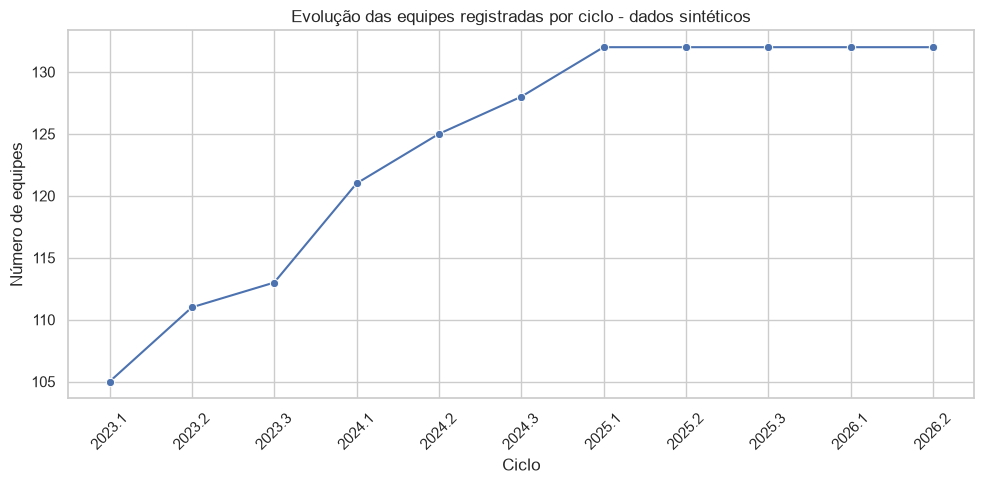

In [8]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=participacao_ciclo,
    x="ciclo",
    y="equipes",
    marker="o"
)

plt.title("Evolução das equipes registradas por ciclo - dados sintéticos")
plt.xlabel("Ciclo")
plt.ylabel("Número de equipes")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [9]:
base_analitica["ciclo"].dtype

<StringDtype(storage='python', na_value=nan)>

### Taxa de desclassificação por ciclo

- Como o número de equipes registradas varia entre os ciclos, a proporção de equipes desclassificadas permite uma comparação mais adequada do que a utilização apenas dos valores absolutos.

In [10]:
taxa_desclassificacao = (
    base_analitica
    .groupby("ciclo")
    .agg(
        total_equipes=("codigo_ine", "size"),
        desclassificadas=(
            "situacao_participacao",
            lambda x: (x == "Desclassificada").sum()
        )
    )
    .reset_index()
)

taxa_desclassificacao["taxa_desclassificacao"] = (
    taxa_desclassificacao["desclassificadas"]
    / taxa_desclassificacao["total_equipes"]
    * 100
)

taxa_desclassificacao

,ciclo,total_equipes,desclassificadas,taxa_desclassificacao
0,2023.1,105,5,4.761905
1,2023.2,111,6,5.405405
2,2023.3,113,1,0.884956
3,2024.1,121,6,4.958678
4,2024.2,125,6,4.800000
5,2024.3,128,4,3.125000
6,2025.1,132,7,5.303030
7,2025.2,132,6,4.545455
8,2025.3,132,7,5.303030
9,2026.1,132,6,4.545455


### Interpretação

- A taxa de desclassificação permanece relativamente baixa ao longo dos ciclos analisados, variando entre aproximadamente 0,9% e 5,4%.
- Não se observa uma tendência contínua de aumento ou redução das desclassificações, mas oscilações entre os diferentes ciclos.
- Esses registros não devem ser interpretados como desempenho igual a zero. Nas análises de pontuação, equipes desclassificadas e registros sem pontuação válida serão excluídos dos cálculos de desempenho.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos.

## 4. Evolução do desempenho ao longo dos ciclos

- Após analisar a participação das equipes, esta etapa investiga a evolução da pontuação final ao longo dos ciclos.
- Para evitar distorções, os cálculos consideram apenas registros com pontuação final válida, equipes desclassificadas ou registros sem pontuação não são tratados como pontuação zero.

In [11]:
desempenho_ciclo = (
    base_analitica
    .groupby("ciclo")
    .agg(
        pontuacoes_validas=("pontuacao_final", "count"),
        media=("pontuacao_final", "mean"),
        mediana=("pontuacao_final", "median")
    )
    .reset_index()
)

desempenho_ciclo

,ciclo,pontuacoes_validas,media,mediana
0,2023.1,100,601.423000,605.65
1,2023.2,105,618.534286,622.80
2,2023.3,110,620.950909,623.75
3,2024.1,115,622.002609,635.30
4,2024.2,119,608.530252,608.20
5,2024.3,124,650.800806,655.95
6,2025.1,125,659.516000,661.20
7,2025.2,126,658.460317,655.00
8,2025.3,125,661.969600,658.30
9,2026.1,126,668.802381,675.35


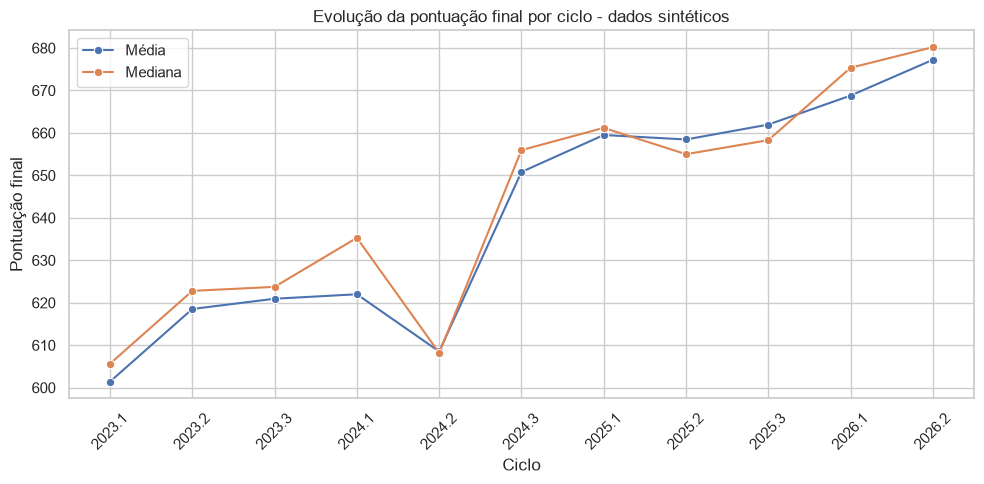

In [12]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=desempenho_ciclo,
    x="ciclo",
    y="media",
    marker="o",
    label="Média"
)

sns.lineplot(
    data=desempenho_ciclo,
    x="ciclo",
    y="mediana",
    marker="o",
    label="Mediana"
)

plt.title("Evolução da pontuação final por ciclo - dados sintéticos")
plt.xlabel("Ciclo")
plt.ylabel("Pontuação final")
plt.xticks(rotation=45)
plt.legend(title="")
plt.tight_layout()

plt.show()

In [13]:
desempenho_eixos = (
    base_analitica
    .groupby("ciclo")
    .agg(
        eixo1_medio=("eixo1_total", "mean"),
        eixo2_medio=("eixo2_total", "mean"),
        eixo3_medio=("eixo3_total", "mean")
    )
    .reset_index()
)

desempenho_eixos

,ciclo,eixo1_medio,eixo2_medio,eixo3_medio
0,2023.1,114.693000,127.741860,356.156000
1,2023.2,116.609524,129.636735,371.797143
2,2023.3,117.984821,130.987719,370.643750
3,2024.1,119.305217,130.466087,372.231304
4,2024.2,114.801681,130.409244,363.319328
5,2024.3,127.600000,131.662097,391.538710
6,2025.1,128.312000,133.113600,398.090400
7,2025.2,128.657937,128.166667,401.635714
8,2025.3,130.164800,128.854400,402.950400
9,2026.1,131.492857,129.286508,408.023016


In [14]:
desempenho_eixos["eixo1_pct"] = (
    desempenho_eixos["eixo1_medio"] / 200 * 100
)

desempenho_eixos["eixo2_pct"] = (
    desempenho_eixos["eixo2_medio"] / 200 * 100
)

desempenho_eixos["eixo3_pct"] = (
    desempenho_eixos["eixo3_medio"] / 600 * 100
)

desempenho_eixos[
    ["ciclo", "eixo1_pct", "eixo2_pct", "eixo3_pct"]
].round(2)

,ciclo,eixo1_pct,eixo2_pct,eixo3_pct
0,2023.1,57.35,63.87,59.36
1,2023.2,58.30,64.82,61.97
2,2023.3,58.99,65.49,61.77
3,2024.1,59.65,65.23,62.04
4,2024.2,57.40,65.20,60.55
5,2024.3,63.80,65.83,65.26
6,2025.1,64.16,66.56,66.35
7,2025.2,64.33,64.08,66.94
8,2025.3,65.08,64.43,67.16
9,2026.1,65.75,64.64,68.00


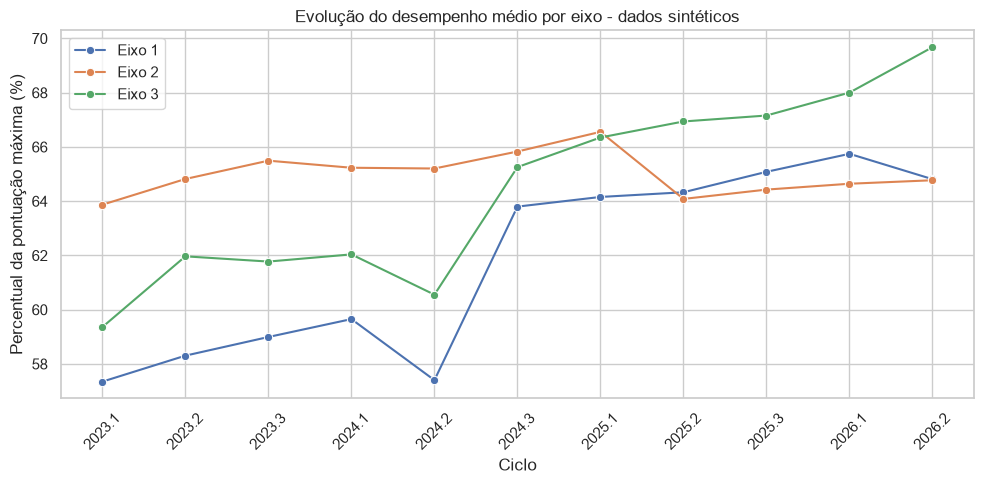

In [15]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=desempenho_eixos,
    x="ciclo",
    y="eixo1_pct",
    marker="o",
    label="Eixo 1"
)

sns.lineplot(
    data=desempenho_eixos,
    x="ciclo",
    y="eixo2_pct",
    marker="o",
    label="Eixo 2"
)

sns.lineplot(
    data=desempenho_eixos,
    x="ciclo",
    y="eixo3_pct",
    marker="o",
    label="Eixo 3"
)

plt.title("Evolução do desempenho médio por eixo - dados sintéticos")
plt.xlabel("Ciclo")
plt.ylabel("Percentual da pontuação máxima (%)")
plt.xticks(rotation=45)
plt.legend(title="")
plt.tight_layout()

plt.show()

### Interpretação

- A comparação dos eixos em relação às suas respectivas pontuações máximas evidencia comportamentos distintos ao longo dos ciclos.
- O Eixo 3 apresenta a maior evolução no período, passando de aproximadamente 59,4% da pontuação máxima em 2023.1 para 69,7% em 2026.2. O Eixo 1 também apresenta crescimento, passando de 57,4% para 64,8%, apesar de uma queda expressiva em 2024.2 seguida de recuperação em 2024.3.
- O Eixo 2 apresenta maior estabilidade ao longo do período, permanecendo, em geral, próximo de 64% a 66% da pontuação máxima.
- A redução observada na pontuação final em 2024.2 coincide principalmente com quedas nos Eixos 1 e 3, enquanto o desempenho médio do Eixo 2 permanece praticamente estável.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos e não representam o desempenho real das equipes do Recife Monitora.

## 5. Distribuição da pontuação final

- Após analisar a evolução das médias e medianas ao longo dos ciclos, é importante observar a distribuição das pontuações entre as equipes.
- Essa análise permite verificar a dispersão dos resultados, possíveis valores extremos e mudanças na distribuição das pontuações ao longo do período.

**Pergunta de análise:** como a distribuição da pontuação final das equipes se comporta ao longo dos ciclos?

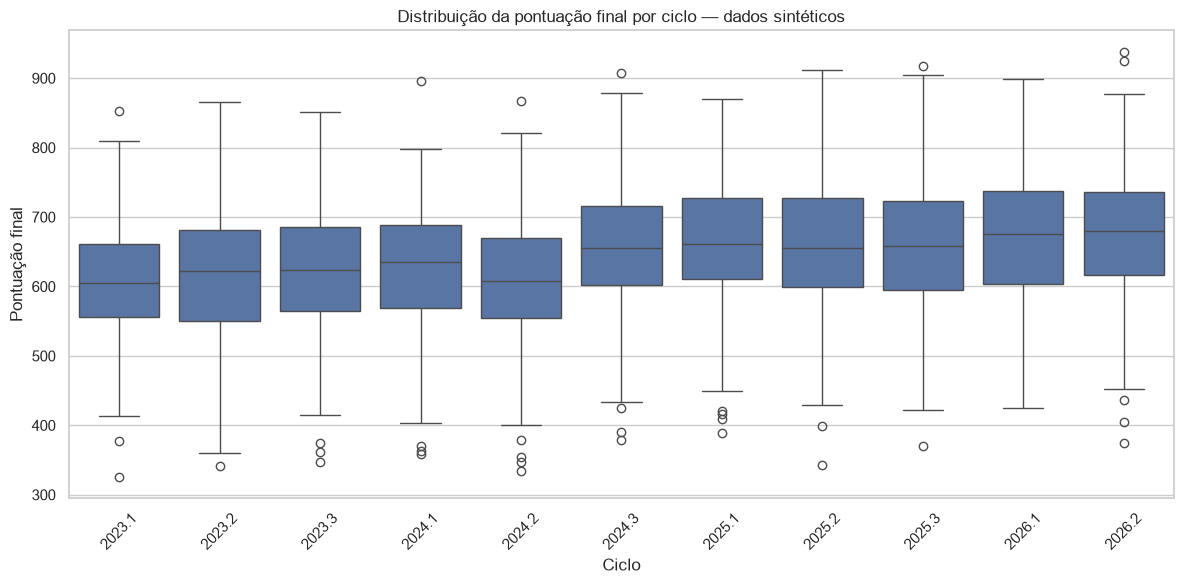

In [16]:
ordem_ciclos = sorted(base_analitica["ciclo"].dropna().unique())

ordem_ciclos

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=base_analitica,
    x="ciclo",
    y="pontuacao_final",
    order=ordem_ciclos
)

plt.title("Distribuição da pontuação final por ciclo — dados sintéticos")
plt.xlabel("Ciclo")
plt.ylabel("Pontuação final")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


### Interpretação

- A distribuição das pontuações finais indica uma tendência geral de aumento da mediana ao longo dos ciclos, apesar de oscilações durante o período. Destaca-se a redução observada em 2024.2, seguida de recuperação em 2024.3, comportamento também identificado anteriormente na análise das médias.
- A amplitude das caixas e das hastes mostra que existe dispersão entre as pontuações das equipes em todos os ciclos, indicando que equipes presentes em um mesmo período podem apresentar desempenhos distintos.
- Também são observados valores isolados abaixo e acima dos limites dos boxplots em diferentes ciclos. Esses pontos representam potenciais valores extremos segundo o critério estatístico do gráfico e não devem ser considerados automaticamente como erros nos dados.

>> **Nota:** os resultados apresentados são provenientes de dados sintéticos e não representam o desempenho real das equipes do Recife Monitora.

## 6. Análise do desempenho por distrito sanitário

- Além da evolução temporal, é importante investigar como o desempenho se distribui entre os diferentes distritos sanitários.
- Nesta etapa são analisadas a média, a mediana, o desvio-padrão e a quantidade de pontuações válidas em cada distrito.

**Pergunta de análise:** existem diferenças no desempenho das equipes entre os distritos sanitários na base analisada?

In [17]:
estatisticas_distrito = (
    base_analitica
    .groupby("distrito_sanitario")
    .agg(
        equipes_distintas=("codigo_ine", "nunique"),
        contagem=("pontuacao_final", "count"),
        media=("pontuacao_final", "mean"),
        mediana=("pontuacao_final", "median"),
        desvio_padrao=("pontuacao_final", "std")
    )
    .reset_index()
)

estatisticas_distrito[
    ["media", "mediana", "desvio_padrao"]
] = estatisticas_distrito[
    ["media", "mediana", "desvio_padrao"]
].round(2)

estatisticas_distrito

,distrito_sanitario,equipes_distintas,contagem,media,mediana,desvio_padrao
0,Distrito Sanitário I,14,141,676.40,670.70,75.20
1,Distrito Sanitário II,14,138,636.93,662.45,127.01
2,Distrito Sanitário III,14,134,694.35,695.15,105.40
3,Distrito Sanitário IV,16,162,655.70,664.70,124.30
4,Distrito Sanitário V,23,225,594.01,594.00,103.94
5,Distrito Sanitário VI,20,202,618.46,624.60,70.61
6,Distrito Sanitário VII,16,160,661.16,659.20,85.11
7,Distrito Sanitário VIII,15,142,640.29,639.65,79.96


### Observações

### Observações

- Na análise agregada dos ciclos, observam-se diferenças nas pontuações entre os distritos sanitários. O Distrito Sanitário III apresenta a maior média (694,35) e mediana (695,15), enquanto o Distrito Sanitário V apresenta os menores valores, com média e mediana próximas de 594 pontos.
- A dispersão dos resultados também varia entre os distritos. O Distrito Sanitário II apresenta o maior desvio-padrão (127,01), indicando maior variabilidade das pontuações, enquanto o Distrito Sanitário VI apresenta o menor desvio-padrão (70,61).
- A quantidade de equipes cadastradas varia entre os distritos, de 14 a 23 equipes. Já a coluna `contagem` representa o número de pontuações finais válidas acumuladas ao longo dos diferentes ciclos, e não o número de equipes distintas.
- Como esta análise reúne diferentes períodos, os resultados representam uma visão agregada da base e não devem ser interpretados como um ranking definitivo entre os distritos.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos.

### Distribuição da pontuação por distrito sanitário

**Pergunta de análise:** como as pontuações finais se distribuem entre os diferentes distritos sanitários?

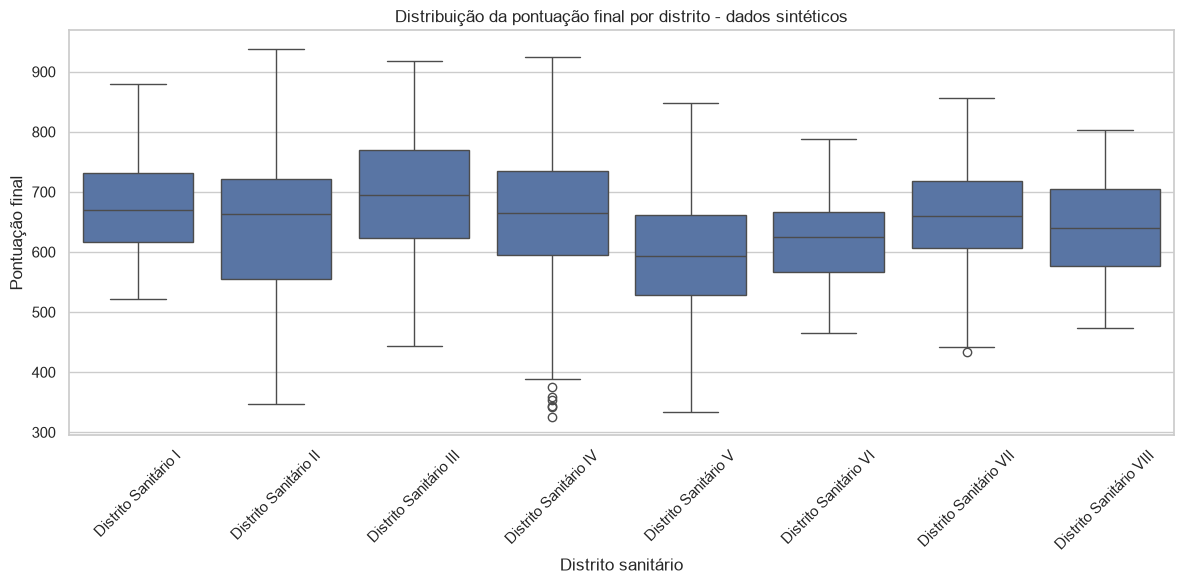

In [18]:
ordem_distritos = [
    "Distrito Sanitário I",
    "Distrito Sanitário II",
    "Distrito Sanitário III",
    "Distrito Sanitário IV",
    "Distrito Sanitário V",
    "Distrito Sanitário VI",
    "Distrito Sanitário VII",
    "Distrito Sanitário VIII"
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=base_analitica,
    x="distrito_sanitario",
    y="pontuacao_final",
    order=ordem_distritos
)

plt.title("Distribuição da pontuação final por distrito - dados sintéticos")
plt.xlabel("Distrito sanitário")
plt.ylabel("Pontuação final")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Interpretação

- A distribuição das pontuações reforça as diferenças observadas nas estatísticas descritivas entre os distritos sanitários.
- O Distrito Sanitário III apresenta a maior mediana de pontuação, enquanto o Distrito Sanitário V apresenta a menor. Entretanto, existe sobreposição considerável entre as distribuições dos diferentes distritos, indicando que as pontuações das equipes não formam grupos completamente distintos entre as regiões.
- Também são observadas diferenças na dispersão dos resultados, os Distritos Sanitários II e IV apresentam maior variabilidade das pontuações, enquanto distritos como I, VI e VIII apresentam distribuições mais concentradas.
- Alguns valores potenciais extremos também são identificados pelo boxplot, especialmente no Distrito Sanitário IV. Esses valores não são considerados automaticamente erros, mas observações que se afastam do padrão central da distribuição.
- Como os dados de diferentes ciclos estão agregados nesta visualização, os resultados representam uma visão geral da base sintética e não devem ser interpretados como um ranking definitivo de desempenho entre os distritos.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos.

## 7. Análise do desempenho por unidade

- Após a análise por distrito sanitário, esta etapa detalha o desempenho no nível das unidades de saúde.
- São calculadas estatísticas descritivas por unidade, incluindo média, mediana, desvio-padrão, quantidade de pontuações válidas e número de equipes distintas.

**Pergunta de análise:** como o desempenho das equipes se distribui entre as diferentes unidades presentes na base?

In [19]:
estatisticas_unidade = (
    base_analitica
    .groupby("nome_unidade")
    .agg(
        equipes_distintas=("codigo_ine", "nunique"),
        contagem=("pontuacao_final", "count"),
        media=("pontuacao_final", "mean"),
        mediana=("pontuacao_final", "median"),
        desvio_padrao=("pontuacao_final", "std")
    )
    .reset_index()
)

estatisticas_unidade[
    ["media", "mediana", "desvio_padrao"]
] = estatisticas_unidade[
    ["media", "mediana", "desvio_padrao"]
].round(2)

print("Número de unidades:", estatisticas_unidade["nome_unidade"].nunique())

estatisticas_unidade.describe()



Número de unidades: 74


,equipes_distintas,contagem,media,mediana,desvio_padrao
count,74.000000,74.000000,74.000000,74.000000,74.000000
mean,1.783784,17.621622,643.513784,641.810135,57.168514
std,1.161839,11.820232,83.788195,87.709918,23.487460
min,1.000000,6.000000,385.440000,374.800000,25.420000
25%,1.000000,10.000000,594.700000,596.550000,41.282500
50%,1.000000,11.000000,657.380000,645.725000,48.480000
75%,2.000000,22.000000,696.902500,697.812500,64.690000
max,6.000000,60.000000,880.150000,881.550000,128.050000


In [20]:
estatisticas_unidade.sort_values(
    "contagem"
).head(10)

,nome_unidade,equipes_distintas,contagem,media,mediana,desvio_padrao
18,USF VIII-624,1,6,711.13,705.05,43.71
61,USF VII-425,1,6,604.50,606.50,25.42
52,USF V-888,1,6,564.38,577.70,36.27
3,USF II-576,1,7,836.74,810.30,56.32
17,USF VIII-427,1,7,742.71,736.50,36.93
60,USF VII-038,1,8,781.55,777.60,42.55
28,USF II-793,1,8,673.79,662.65,44.62
23,USF I-994,1,8,704.30,706.10,50.03
57,USF VI-599,1,8,597.52,590.80,65.07
72,USF VIII-907,1,8,604.31,599.85,44.48


### Observações

- A base contém 74 unidades de saúde, com diferenças importantes na quantidade de equipes e de observações disponíveis para cada unidade.
- O número de equipes distintas por unidade varia de 1 a 6, sendo que a mediana é de 1 equipe. A quantidade de pontuações finais válidas varia de 6 a 60 registros por unidade, com mediana de 11 registros.
- As médias de pontuação também apresentam variação entre as unidades. Entretanto, essas diferenças devem ser interpretadas com cautela, pois algumas unidades possuem poucas equipes e menor quantidade de observações ao longo dos ciclos. Dessa forma, uma média elevada ou reduzida em uma unidade com poucos registros não possui a mesma representatividade de uma média calculada a partir de uma quantidade maior de observações.
- Por esse motivo, optou-se por utilizar as estatísticas descritivas para caracterizar o desempenho no nível das unidades, evitando a construção de um ranking direto entre as 74 unidades.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos.

In [21]:
estatisticas_unidade.sort_values(
    "nome_unidade"
).reset_index(drop=True)

,nome_unidade,equipes_distintas,contagem,media,mediana,desvio_padrao
0,USF I-295,1,10,629.46,629.25,45.34
1,USF I-343,1,11,613.78,600.10,43.88
2,USF II-411,1,10,664.46,663.05,25.93
3,USF II-576,1,7,836.74,810.30,56.32
4,USF II-840,1,10,663.86,662.60,42.45
...,...,...,...,...,...,...
69,USF VIII-211,3,26,663.17,668.20,81.28
70,USF VIII-497,3,30,611.88,603.20,84.31
71,USF VIII-668,1,11,614.57,599.70,54.08
72,USF VIII-907,1,8,604.31,599.85,44.48


## 8. Evolução do desempenho por distrito sanitário

- Após analisar as diferenças agregadas entre os distritos sanitários, esta etapa incorpora a dimensão temporal para verificar como o desempenho evolui ao longo dos ciclos.

**Pergunta de análise:** como a pontuação média dos diferentes distritos sanitários evolui ao longo dos ciclos?

In [22]:
distrito_ciclo = (
    base_analitica
    .groupby(["ciclo", "distrito_sanitario"])
    .agg(
        pontuacoes_validas=("pontuacao_final", "count"),
        media=("pontuacao_final", "mean")
    )
    .reset_index()
)

distrito_ciclo["media"] = distrito_ciclo["media"].round(2)

distrito_ciclo.head(16)

,ciclo,distrito_sanitario,pontuacoes_validas,media
0,2023.1,Distrito Sanitário I,12,630.30
1,2023.1,Distrito Sanitário II,10,579.11
2,2023.1,Distrito Sanitário III,11,668.40
3,2023.1,Distrito Sanitário IV,13,603.22
4,2023.1,Distrito Sanitário V,17,561.86
5,2023.1,Distrito Sanitário VI,14,580.74
6,2023.1,Distrito Sanitário VII,13,608.79
7,2023.1,Distrito Sanitário VIII,10,599.69
8,2023.2,Distrito Sanitário I,12,661.46
9,2023.2,Distrito Sanitário II,10,593.45


In [23]:
distrito_ciclo.groupby("distrito_sanitario")["pontuacoes_validas"].agg(
    ["min", "max"]
)

,min,max
distrito_sanitario,,
Distrito Sanitário I,12,14
Distrito Sanitário II,10,14
Distrito Sanitário III,10,14
Distrito Sanitário IV,13,16
Distrito Sanitário V,17,23
Distrito Sanitário VI,14,20
Distrito Sanitário VII,13,16
Distrito Sanitário VIII,10,15


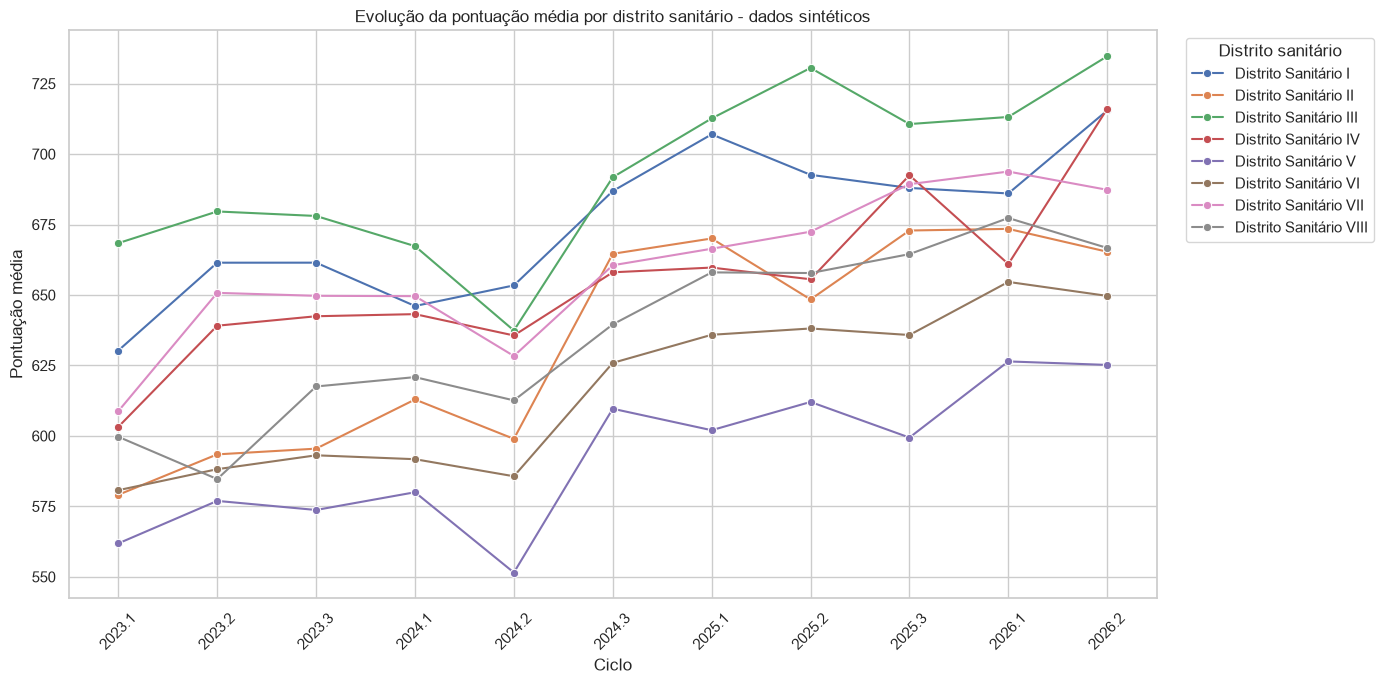

In [24]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=distrito_ciclo,
    x="ciclo",
    y="media",
    hue="distrito_sanitario",
    marker="o"
)

plt.title("Evolução da pontuação média por distrito sanitário - dados sintéticos")
plt.xlabel("Ciclo")
plt.ylabel("Pontuação média")
plt.xticks(rotation=45)
plt.legend(
    title="Distrito sanitário",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

### Interpretação

- A análise temporal mostra que os distritos sanitários apresentam trajetórias distintas ao longo dos ciclos, embora seja possível observar uma tendência geral de aumento das pontuações médias no período analisado.
- O Distrito Sanitário III permanece entre as maiores médias durante grande parte da série e encerra o período com a maior pontuação média. Em sentido oposto, o Distrito Sanitário V apresenta médias inferiores às dos demais distritos ao longo de praticamente todo o período, apesar de também apresentar evolução em relação aos primeiros ciclos.
- O ciclo 2024.2 chama atenção por apresentar redução da pontuação média em diversos distritos, seguida de recuperação em 2024.3. Esse comportamento é coerente com a queda observada anteriormente na análise geral das pontuações.
- Também é possível observar que as diferenças entre os distritos não permanecem constantes. Em alguns momentos as trajetórias se aproximam ou se cruzam, indicando que a posição relativa dos distritos varia ao longo dos ciclos.
- As diferenças observadas são descritivas e não permitem estabelecer relações de causa e efeito. Além disso, a quantidade de pontuações válidas varia entre os distritos e ciclos, embora a verificação realizada tenha mostrado pelo menos 10 observações válidas em cada combinação analisada.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos e não representam o desempenho real dos distritos sanitários do Recife.

## 9. Análise dos indicadores do Eixo 3 por grupo

- O Eixo 3 é composto por indicadores cujos pesos podem variar de acordo com o grupo ao qual cada equipe pertence. Dessa forma, a análise dos indicadores deve considerar essa estrutura para evitar comparações inadequadas entre equipes submetidas a diferentes composições de avaliação.
- Nesta etapa, os dados detalhados do Eixo 3 são associados ao grupo de cada equipe para permitir análises dentro de grupos comparáveis.

**Pergunta de análise:** como os resultados dos indicadores do Eixo 3 se comportam entre as equipes pertencentes aos diferentes grupos?

In [25]:
eixo3_grupo = eixo3.merge(
    equipes[["codigo_ine", "grupo"]],
    on="codigo_ine",
    how="left",
    validate="many_to_one"
)

print("Dimensão da base:", eixo3_grupo.shape)
print("Grupos encontrados:", sorted(eixo3_grupo["grupo"].dropna().unique()))
print("Registros sem grupo:", eixo3_grupo["grupo"].isna().sum())

eixo3_grupo.head()

Dimensão da base: (13294, 8)
Grupos encontrados: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Registros sem grupo: 0


,codigo_ine,ciclo,codigo_indicador,indicador,peso_maximo,percentual_alcancado,pontos_obtidos,grupo
0,6000000000,2023.1,IND01,Proporção de gestantes com 6 ou mais consultas...,75,0.6223,46.7,2
1,6000000000,2023.1,IND02,Proporção de gestantes com exames de sífilis e...,70,0.7733,54.1,2
2,6000000000,2023.1,IND03,Proporção de gestantes com atendimento odontol...,55,0.8604,47.3,2
3,6000000000,2023.1,IND04,Cobertura de exame citopatológico do colo do ú...,70,0.6073,42.5,2
4,6000000000,2023.1,IND05,Cobertura vacinal de poliomielite e pentavalen...,75,0.6256,46.9,2


In [26]:
estrutura_eixo3_grupo = (
    eixo3_grupo
    .groupby(["grupo", "codigo_indicador"])
    .agg(
        peso_maximo=("peso_maximo", "first"),
        registros=("codigo_ine", "count"),
        equipes=("codigo_ine", "nunique")
    )
    .reset_index()
)

estrutura_eixo3_grupo

,grupo,codigo_indicador,peso_maximo,registros,equipes
0,1,IND01,70,396,38
1,1,IND02,65,396,38
2,1,IND03,60,396,38
3,1,IND04,65,396,38
4,1,IND05,70,396,38
5,1,IND06,65,396,38
6,1,IND07,60,396,38
7,1,IND08,55,396,38
8,1,IND09,50,396,38
9,1,IND10,40,396,38


In [27]:
desempenho_indicadores_grupo = (
    eixo3_grupo
    .groupby(["grupo", "codigo_indicador"])
    .agg(
        registros=("percentual_alcancado", "count"),
        media_percentual=("percentual_alcancado", "mean"),
        mediana_percentual=("percentual_alcancado", "median"),
        desvio_padrao=("percentual_alcancado", "std")
    )
    .reset_index()
)

desempenho_indicadores_grupo[
    ["media_percentual", "mediana_percentual", "desvio_padrao"]
] = (
    desempenho_indicadores_grupo[
        ["media_percentual", "mediana_percentual", "desvio_padrao"]
    ] * 100
).round(2)

desempenho_indicadores_grupo

,grupo,codigo_indicador,registros,media_percentual,mediana_percentual,desvio_padrao
0,1,IND01,396,64.85,64.47,15.97
1,1,IND02,396,64.98,65.66,15.30
2,1,IND03,396,65.16,65.08,16.44
3,1,IND04,396,64.50,64.49,16.35
4,1,IND05,396,66.36,67.40,16.95
5,1,IND06,396,63.96,64.94,16.83
6,1,IND07,396,65.08,64.78,15.69
7,1,IND08,396,64.26,63.23,16.89
8,1,IND09,396,65.24,65.81,16.23
9,1,IND10,396,66.10,67.16,16.67


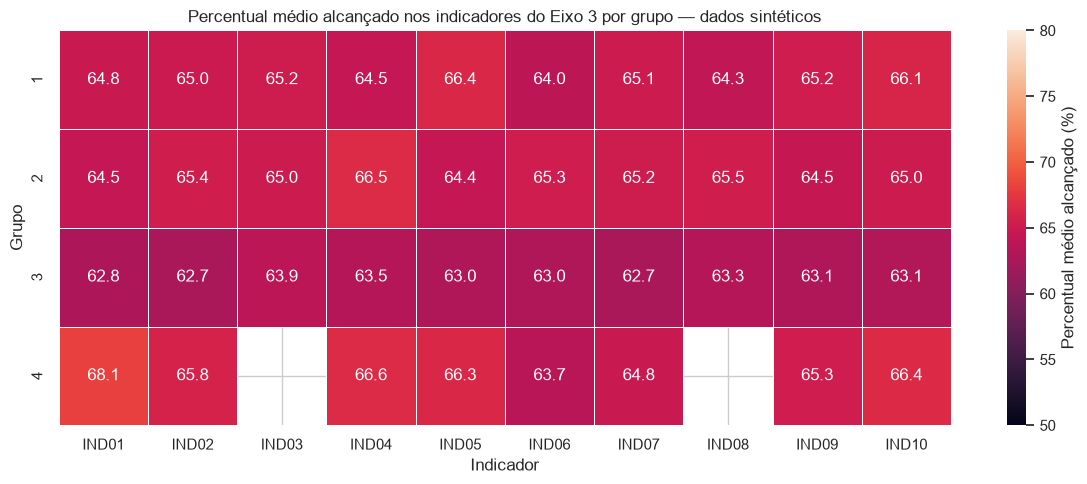

In [28]:
tabela_heatmap = (
    desempenho_indicadores_grupo
    .pivot(
        index="grupo",
        columns="codigo_indicador",
        values="media_percentual"
    )
)

plt.figure(figsize=(12, 5))

sns.heatmap(
    tabela_heatmap,
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    vmin=50,
    vmax=80,
    cbar_kws={"label": "Percentual médio alcançado (%)"}
)

plt.title(
    "Percentual médio alcançado nos indicadores do Eixo 3 por grupo — dados sintéticos"
)
plt.xlabel("Indicador")
plt.ylabel("Grupo")
plt.tight_layout()
plt.show()
plt.show()

### Interpretação

- O mapa de calor mostra que os percentuais médios alcançados nos indicadores do Eixo 3 são relativamente próximos, concentrando-se aproximadamente entre 63% e 68%.
- Nos Grupos 1 e 2, os resultados permanecem predominantemente próximos de 65%. O Grupo 3 apresenta percentuais ligeiramente menores e bastante homogêneos entre os indicadores. No Grupo 4, observa-se uma variação um pouco maior, com o IND01 apresentando o maior percentual médio dentro desse grupo.
- A análise utiliza o percentual alcançado, e não diretamente os pontos obtidos, pois os pesos máximos dos indicadores variam conforme o grupo da equipe. Dessa forma, evita-se comparar diretamente pontuações calculadas a partir de pesos diferentes.
- No Grupo 4, os indicadores IND03 e IND08 não fazem parte da composição da avaliação. Portanto, as células sem valor correspondentes a esses indicadores representam uma regra de negócio e não dados ausentes por problemas de qualidade.
- Embora o mapa de calor permita identificar pequenas diferenças nos percentuais, os resultados são relativamente próximos. Além disso, os grupos possuem composições e pesos distintos, portanto a visualização não deve ser interpretada como um ranking de desempenho entre os grupos.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos.

## 10. Relação entre características das equipes e desempenho

- Além das análises temporais e territoriais, é importante investigar se características das equipes apresentam alguma relação com a pontuação obtida.
- Nesta etapa, são utilizados gráficos de dispersão para explorar possíveis associações entre variáveis numéricas e o desempenho das equipes.

**Pergunta de análise:** existe alguma relação aparente entre a população adscrita à equipe e sua pontuação final?

In [29]:
relacao_populacao = (
    base_analitica[
        ["codigo_ine", "ciclo", "populacao_adscrita", "pontuacao_final"]
    ]
    .dropna(subset=["populacao_adscrita", "pontuacao_final"])
)

print("Observações válidas:", len(relacao_populacao))
print("Equipes distintas:", relacao_populacao["codigo_ine"].nunique())

relacao_populacao[
    ["populacao_adscrita", "pontuacao_final"]
].describe().round(2)

Observações válidas: 1203
Equipes distintas: 121


,populacao_adscrita,pontuacao_final
count,1203.00,1203.00
mean,3989.14,648.52
std,2062.81,101.76
min,900.00,325.40
25%,2612.00,590.10
50%,3444.00,652.20
75%,5235.00,715.95
max,10847.00,938.10


In [30]:
relacao_populacao_equipe = (
    relacao_populacao
    .groupby("codigo_ine")
    .agg(
        populacao_adscrita=("populacao_adscrita", "first"),
        pontuacao_media=("pontuacao_final", "mean"),
        ciclos_validos=("pontuacao_final", "count")
    )
    .reset_index()
)

relacao_populacao_equipe["pontuacao_media"] = (
    relacao_populacao_equipe["pontuacao_media"].round(2)
)

print("Equipes analisadas:", len(relacao_populacao_equipe))

relacao_populacao_equipe.describe().round(2)

Equipes analisadas: 121


,populacao_adscrita,pontuacao_media,ciclos_validos
count,121.00,121.00,121.00
mean,3930.57,649.42,9.94
std,2042.46,93.02,1.47
min,900.00,385.44,4.00
25%,2606.00,603.83,10.00
50%,3441.00,650.23,10.00
75%,5148.00,708.67,11.00
max,10847.00,880.15,11.00


In [31]:
correlacao_populacao = (
    relacao_populacao_equipe["populacao_adscrita"]
    .corr(relacao_populacao_equipe["pontuacao_media"])
)

print(f"Correlação de Pearson: {correlacao_populacao:.3f}")

Correlação de Pearson: -0.019


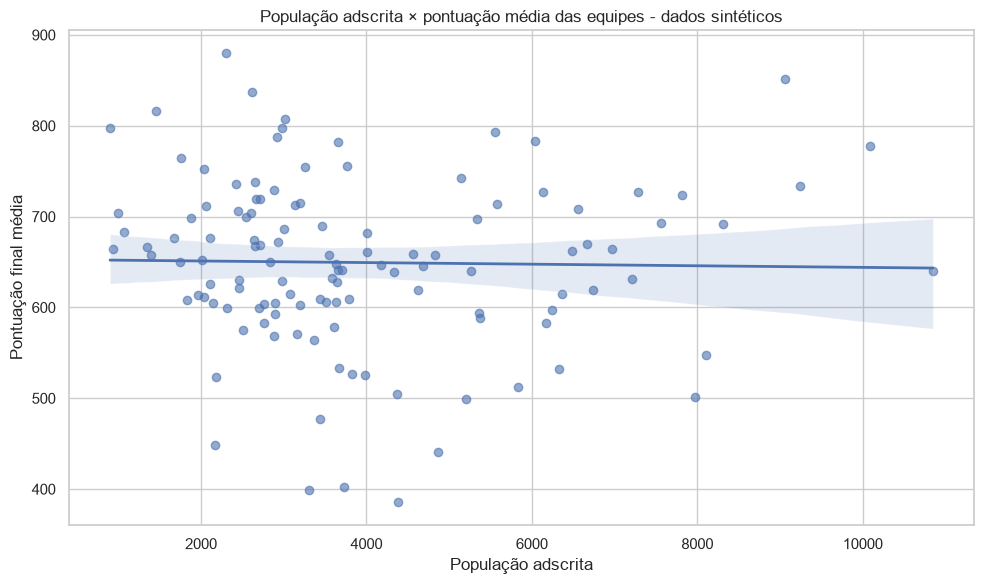

In [32]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=relacao_populacao_equipe,
    x="populacao_adscrita",
    y="pontuacao_media",
    scatter_kws={"alpha": 0.6},
    line_kws={"linewidth": 2}
)

plt.title(
    "População adscrita × pontuação média das equipes - dados sintéticos"
)
plt.xlabel("População adscrita")
plt.ylabel("Pontuação final média")
plt.tight_layout()
plt.show()

### Interpretação

- O gráfico de dispersão não indica uma relação linear aparente entre a população adscrita e a pontuação média das equipes.
- A correlação de Pearson calculada foi de **-0,019**, valor muito próximo de zero, reforçando a ausência de uma associação linear relevante entre as duas variáveis na base analisada. Visualmente, as equipes apresentam pontuações bastante variadas em diferentes tamanhos de população adscrita, sem uma tendência clara de aumento ou redução da pontuação conforme a população cresce.
- Para evitar que uma mesma equipe fosse representada repetidamente pelos diferentes ciclos, a análise foi realizada com uma observação por equipe. A pontuação utilizada corresponde à média dos ciclos válidos de cada equipe. Foram analisadas 121 equipes, que possuem entre 4 e 11 ciclos válidos, com mediana de 10 ciclos.
- O resultado não significa que a população adscrita não possa ter qualquer relação com o desempenho das equipes, mas apenas que **não foi identificada uma associação linear relevante entre essas duas variáveis nesta base sintética**. Além disso, correlação não implica relação de causa e efeito.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos.

## 11. Qualidade e completude dos dados

- A etapa de preparação dos dados identificou e tratou inconsistências de formato, duplicidades e problemas de integridade referencial. Entretanto, alguns valores ausentes foram preservados por representarem situações previstas pelas regras de negócio, e não necessariamente erros de qualidade.

- Nesta seção, a qualidade da base tratada é apresentada de forma visual, com foco na completude das principais variáveis utilizadas nas análises.

**Pergunta de análise:** quais variáveis da base analítica apresentam maior proporção de valores ausentes após o tratamento dos dados?

In [33]:
colunas_qualidade = [
    "populacao_adscrita",
    "eixo1_total",
    "eixo2_total",
    "eixo3_total",
    "pontuacao_final",
    "zona_classificacao"
]

qualidade_dados = pd.DataFrame({
    "variavel": colunas_qualidade,
    "valores_ausentes": [
        base_analitica[col].isna().sum()
        for col in colunas_qualidade
    ],
    "percentual_ausente": [
        base_analitica[col].isna().mean() * 100
        for col in colunas_qualidade
    ]
})

qualidade_dados["percentual_ausente"] = (
    qualidade_dados["percentual_ausente"].round(2)
)

qualidade_dados.sort_values(
    "percentual_ausente",
    ascending=False
)

,variavel,valores_ausentes,percentual_ausente
2,eixo2_total,225,16.51
0,populacao_adscrita,109,8.00
5,zona_classificacao,59,4.33
4,pontuacao_final,59,4.33
1,eixo1_total,57,4.18
3,eixo3_total,57,4.18


In [34]:
pd.crosstab(
    base_analitica["situacao_participacao"],
    base_analitica["pontuacao_final"].isna(),
    margins=True
)

pontuacao_final,False,True,All
situacao_participacao,,,
Desclassificada,0,57,57
Participante,1304,2,1306
All,1304,59,1363


In [35]:
pd.crosstab(
    base_analitica["situacao_participacao"],
    base_analitica["eixo2_total"].isna(),
    margins=True
)

eixo2_total,False,True,All
situacao_participacao,,,
Desclassificada,0,57,57
Participante,1138,168,1306
All,1138,225,1363


In [36]:
base_analitica.loc[
    (base_analitica["situacao_participacao"] == "Participante")
    & (base_analitica["pontuacao_final"].isna()),
    [
        "codigo_ine",
        "ciclo",
        "eixo1_total",
        "eixo2_total",
        "eixo3_total",
        "pontuacao_final",
        "zona_classificacao"
    ]
]

,codigo_ine,ciclo,eixo1_total,eixo2_total,eixo3_total,pontuacao_final,zona_classificacao
291,6000000028,2023.3,97.9,NaN,323.5,NaN,NaN
1137,6000000110,2023.3,123.5,NaN,367.5,NaN,NaN


In [37]:
participantes = base_analitica[
    base_analitica["situacao_participacao"] == "Participante"
]

colunas_qualidade_participantes = [
    "populacao_adscrita",
    "eixo1_total",
    "eixo2_total",
    "eixo3_total",
    "pontuacao_final",
    "zona_classificacao"
]

qualidade_participantes = pd.DataFrame({
    "variavel": colunas_qualidade_participantes,
    "valores_ausentes": [
        participantes[col].isna().sum()
        for col in colunas_qualidade_participantes
    ],
    "percentual_ausente": [
        participantes[col].isna().mean() * 100
        for col in colunas_qualidade_participantes
    ]
})

qualidade_participantes["percentual_ausente"] = (
    qualidade_participantes["percentual_ausente"].round(2)
)

qualidade_participantes.sort_values(
    "percentual_ausente",
    ascending=False
)

,variavel,valores_ausentes,percentual_ausente
2,eixo2_total,168,12.86
0,populacao_adscrita,101,7.73
5,zona_classificacao,2,0.15
4,pontuacao_final,2,0.15
1,eixo1_total,0,0.00
3,eixo3_total,0,0.00


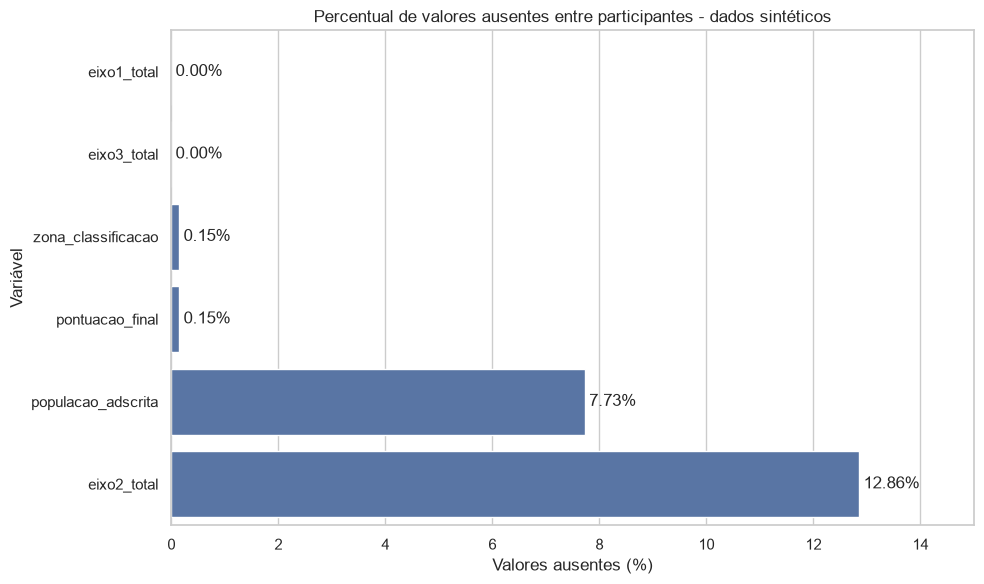

In [38]:
qualidade_plot = (
    qualidade_participantes
    .sort_values("percentual_ausente", ascending=True)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=qualidade_plot,
    x="percentual_ausente",
    y="variavel"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title(
    "Percentual de valores ausentes entre participantes - dados sintéticos"
)
plt.xlabel("Valores ausentes (%)")
plt.ylabel("Variável")
plt.xlim(0, 15)
plt.tight_layout()
plt.show()

### Interpretação

- A análise de completude foi realizada considerando apenas os registros classificados como participantes. Essa decisão evita contabilizar como problemas de qualidade as ausências decorrentes da desclassificação, uma vez que, pelas regras de negócio, equipes desclassificadas não possuem pontuação calculada.
- Entre os participantes, o `eixo2_total` apresenta a maior proporção de valores ausentes, com **168 registros (12,86%)**. A `populacao_adscrita` apresenta **101 registros ausentes (7,73%)**.
- Os campos `eixo1_total` e `eixo3_total` estão completos entre os participantes. Já `pontuacao_final` e `zona_classificacao` apresentam apenas **2 registros ausentes (0,15%)**. A investigação desses dois casos mostrou que ambos correspondem a participantes sem valor disponível para o Eixo 2, impossibilitando o cálculo da pontuação final e, consequentemente, da classificação.
- Essas ausências foram preservadas durante a preparação dos dados, evitando substituições artificiais por zero ou por valores estimados. Dessa forma, os valores ausentes permanecem explicitamente representados nas análises.
- A visualização evidencia também a importância de interpretar valores ausentes considerando as regras de negócio, pois nem toda ausência representa necessariamente um erro de qualidade dos dados.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos.

## 12. Análise dos atributos de NPS

- A base de NPS apresenta avaliações associadas a diferentes atributos da experiência, como acolhimento, tempo de espera, resolutividade, estrutura e vínculo.
- Nesta etapa, são analisados os resultados de NPS por atributo, considerando apenas os registros que possuem valor de NPS disponível.

**Pergunta de análise:** existem diferenças nos resultados de NPS entre os atributos avaliados?

In [39]:
estatisticas_nps = (
    nps
    .groupby(["codigo_atributo", "atributo"])
    .agg(
        registros=("nps", "size"),
        nps_validos=("nps", "count"),
        nps_ausentes=("nps", lambda x: x.isna().sum()),
        media_nps=("nps", "mean"),
        mediana_nps=("nps", "median"),
        desvio_padrao=("nps", "std"),
        media_respondentes=("n_respondentes", "mean")
    )
    .reset_index()
)

estatisticas_nps[
    ["media_nps", "mediana_nps", "desvio_padrao", "media_respondentes"]
] = estatisticas_nps[
    ["media_nps", "mediana_nps", "desvio_padrao", "media_respondentes"]
].round(2)

estatisticas_nps

,codigo_atributo,atributo,registros,nps_validos,nps_ausentes,media_nps,mediana_nps,desvio_padrao,media_respondentes
0,ATR1,Acolhimento da equipe,1363,1311,52,41.17,41.10,26.32,43.24
1,ATR2,Tempo de espera para atendimento,1363,1305,58,11.16,11.50,26.56,43.84
2,ATR3,Resolutividade do atendimento,1363,1308,55,33.23,32.75,26.12,43.84
3,ATR4,Estrutura e limpeza da unidade,1363,1313,50,32.77,33.00,26.83,43.80
4,ATR5,Vínculo e confiança com a equipe,1363,1318,45,33.26,33.60,26.27,43.77


In [40]:
nomes_atributos = {
    "ATR1": "Acolhimento",
    "ATR2": "Tempo de espera",
    "ATR3": "Resolutividade",
    "ATR4": "Estrutura e limpeza",
    "ATR5": "Vínculo e confiança"
}

nps_plot = nps.copy()

nps_plot["atributo_resumido"] = (
    nps_plot["codigo_atributo"]
    .map(nomes_atributos)
)

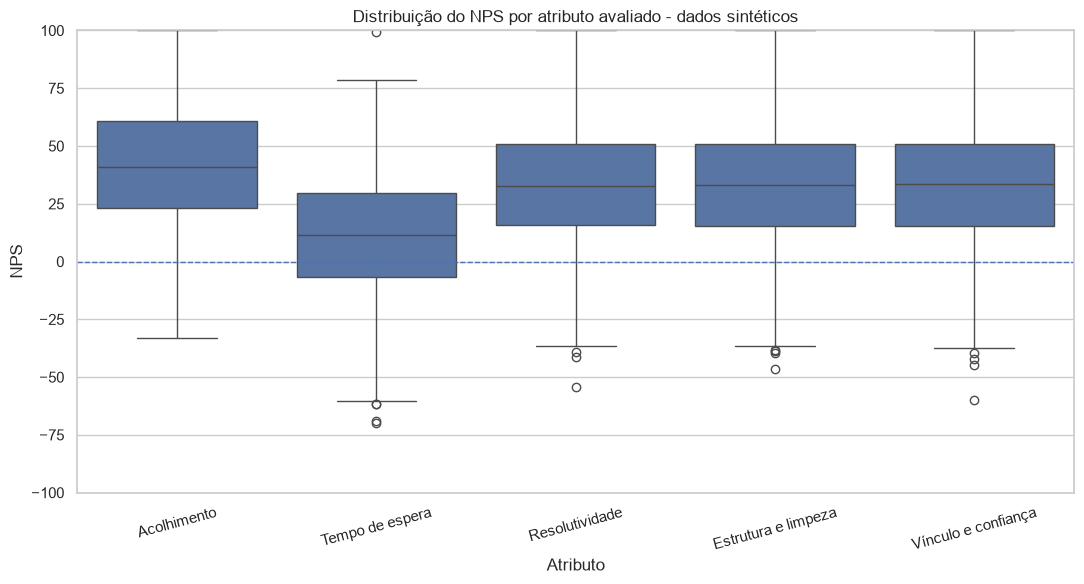

In [41]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=nps_plot,
    x="atributo_resumido",
    y="nps",
    order=list(nomes_atributos.values())
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Distribuição do NPS por atributo avaliado - dados sintéticos"
)
plt.xlabel("Atributo")
plt.ylabel("NPS")
plt.ylim(-100, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Interpretação

- A distribuição do NPS apresenta diferenças entre os atributos avaliados. O atributo **Acolhimento** possui o maior resultado médio, com NPS de 41,17, além de apresentar mediana superior à dos demais atributos.
- O **Tempo de espera** apresenta o menor resultado, com média de 11,16 e mediana de 11,50. Sua distribuição também se encontra deslocada para valores mais baixos, indicando resultados inferiores aos observados nos demais atributos da base sintética.
- Os atributos **Resolutividade**, **Estrutura e limpeza** e **Vínculo e confiança** apresentam comportamento semelhante, com médias próximas de 33 e medianas também bastante próximas.
- Apesar dessas diferenças, todos os atributos apresentam dispersão considerável e registros com NPS negativo. Também são observados valores extremos em alguns atributos, que representam observações estatisticamente distantes da distribuição e não devem ser interpretados automaticamente como erros.
- Foram identificados 260 valores de NPS ausentes, distribuídos entre os cinco atributos. Essas ausências foram preservadas durante a preparação dos dados, sem substituição artificial por zero ou por valores estimados.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos e não representam avaliações reais dos usuários dos serviços de saúde do Recife.

## 13. Análise dos planos de ação

- A base de planos de ação contém informações sobre a avaliação dos planos elaborados pelas equipes, considerando dimensões relacionadas à governança, à estrutura SMART, à viabilidade e ao nível de maturidade.
- Nesta etapa, são investigadas a distribuição dos níveis e dos rótulos de maturidade, bem como o comportamento das dimensões utilizadas na avaliação dos planos.

**Pergunta de análise:** como os planos de ação se distribuem entre os diferentes níveis e rótulos de maturidade?

In [42]:
print("Total de planos:", len(planos))

print("\nNível de maturidade:")
display(
    planos["nivel_maturidade"]
    .value_counts()
    .sort_index()
    .to_frame("quantidade")
)

print("\nRótulo de maturidade:")
display(
    planos["rotulo_maturidade"]
    .value_counts()
    .to_frame("quantidade")
)

print("\nTexto do plano ausente:")
print(planos["texto_plano"].isna().sum())

Total de planos: 420

Nível de maturidade:


,quantidade
nivel_maturidade,
1,122
2,170
3,128



Rótulo de maturidade:


,quantidade
rotulo_maturidade,
Ajustes,170
Aprovado,128
Reformulação,122



Texto do plano ausente:
10


In [43]:
cruzamento_maturidade = pd.crosstab(
    planos["nivel_maturidade"],
    planos["rotulo_maturidade"]
)

cruzamento_maturidade

rotulo_maturidade,Ajustes,Aprovado,Reformulação
nivel_maturidade,,,
1,0,0,122
2,170,0,0
3,0,128,0


In [44]:
ordem_maturidade = [
    "Reformulação",
    "Ajustes",
    "Aprovado"
]

distribuicao_planos = (
    planos["rotulo_maturidade"]
    .value_counts()
    .reindex(ordem_maturidade)
    .reset_index()
)

distribuicao_planos.columns = [
    "rotulo_maturidade",
    "quantidade"
]

distribuicao_planos["percentual"] = (
    distribuicao_planos["quantidade"]
    / distribuicao_planos["quantidade"].sum()
    * 100
).round(1)

distribuicao_planos

,rotulo_maturidade,quantidade,percentual
0,Reformulação,122,29.0
1,Ajustes,170,40.5
2,Aprovado,128,30.5


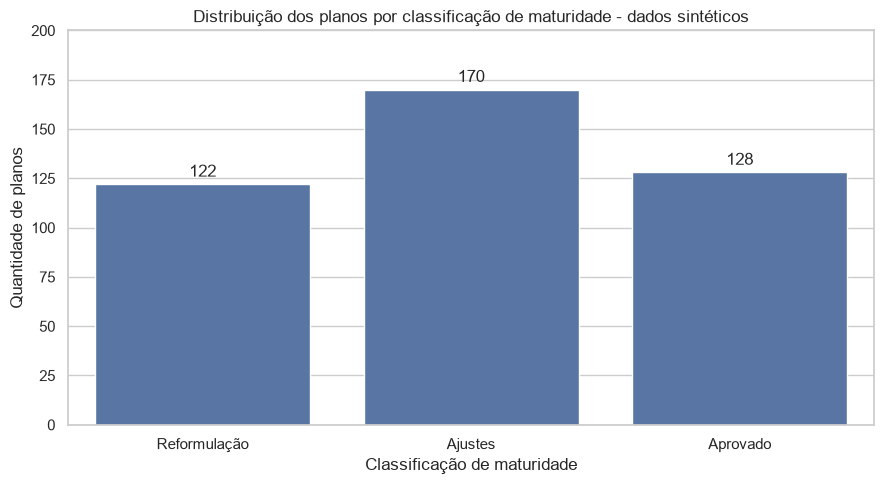

In [45]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=distribuicao_planos,
    x="rotulo_maturidade",
    y="quantidade",
    order=ordem_maturidade
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title(
    "Distribuição dos planos por classificação de maturidade - dados sintéticos"
)
plt.xlabel("Classificação de maturidade")
plt.ylabel("Quantidade de planos")
plt.ylim(0, 200)
plt.tight_layout()
plt.show()

In [46]:
dimensoes_maturidade = (
    planos
    .groupby("rotulo_maturidade")
    .agg(
        media_governanca=("dim_governanca", "mean"),
        media_smart=("dim_smart", "mean"),
        media_viabilidade=("dim_viabilidade", "mean")
    )
    .reindex(ordem_maturidade)
    .round(2)
)

dimensoes_maturidade

,media_governanca,media_smart,media_viabilidade
rotulo_maturidade,,,
Reformulação,1.57,1.48,2.07
Ajustes,2.48,2.46,2.96
Aprovado,3.47,4.45,3.48


In [47]:
dimensoes_normalizadas = dimensoes_maturidade.copy()

dimensoes_normalizadas["Governança (%)"] = (
    (dimensoes_normalizadas["media_governanca"] - 1)
    / (4 - 1)
    * 100
)

dimensoes_normalizadas["SMART (%)"] = (
    (dimensoes_normalizadas["media_smart"] - 1)
    / (5 - 1)
    * 100
)

dimensoes_normalizadas["Viabilidade (%)"] = (
    (dimensoes_normalizadas["media_viabilidade"] - 1)
    / (4 - 1)
    * 100
)

dimensoes_normalizadas = dimensoes_normalizadas[
    ["Governança (%)", "SMART (%)", "Viabilidade (%)"]
].round(1)

dimensoes_normalizadas

,Governança (%),SMART (%),Viabilidade (%)
rotulo_maturidade,,,
Reformulação,19.0,12.0,35.7
Ajustes,49.3,36.5,65.3
Aprovado,82.3,86.2,82.7


In [48]:
dimensoes_plot = (
    dimensoes_normalizadas
    .reset_index()
    .melt(
        id_vars="rotulo_maturidade",
        var_name="dimensao",
        value_name="percentual"
    )
)

dimensoes_plot

,rotulo_maturidade,dimensao,percentual
0,Reformulação,Governança (%),19.0
1,Ajustes,Governança (%),49.3
2,Aprovado,Governança (%),82.3
3,Reformulação,SMART (%),12.0
4,Ajustes,SMART (%),36.5
5,Aprovado,SMART (%),86.2
6,Reformulação,Viabilidade (%),35.7
7,Ajustes,Viabilidade (%),65.3
8,Aprovado,Viabilidade (%),82.7


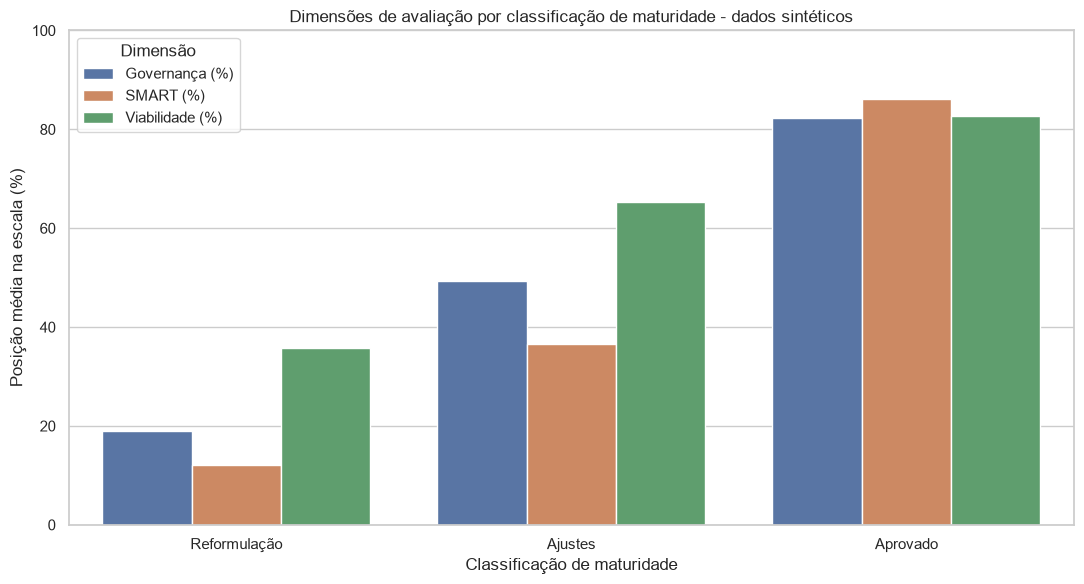

In [49]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=dimensoes_plot,
    x="rotulo_maturidade",
    y="percentual",
    hue="dimensao",
    order=ordem_maturidade
)

plt.title(
    "Dimensões de avaliação por classificação de maturidade - dados sintéticos"
)
plt.xlabel("Classificação de maturidade")
plt.ylabel("Posição média na escala (%)")
plt.ylim(0, 100)
plt.legend(title="Dimensão")
plt.tight_layout()
plt.show()

### Interpretação

- Os 420 planos de ação estão distribuídos entre as três classificações de maturidade, com maior concentração na categoria **Ajustes**, que reúne 170 planos (40,5%). Os planos classificados como **Aprovado** correspondem a 128 registros (30,5%), enquanto **Reformulação** reúne 122 planos (29,0%).
- Foi verificada também a correspondência entre o nível numérico e o rótulo de maturidade. O nível 1 corresponde integralmente à classificação Reformulação, o nível 2 à classificação Ajustes e o nível 3 à classificação Aprovado.
- Para comparar as dimensões de Governança, SMART e Viabilidade, as médias foram normalizadas de acordo com suas respectivas escalas, uma vez que Governança e Viabilidade variam de 1 a 4, enquanto SMART varia de 1 a 5.
- Após a normalização, observa-se um aumento consistente nas três dimensões conforme cresce o nível de maturidade dos planos. Os planos classificados como Reformulação apresentam posições médias de 19,0% em Governança, 12,0% em SMART e 35,7% em Viabilidade. Entre os planos classificados como Ajustes, esses valores aumentam para 49,3%, 36,5% e 65,3%, respectivamente.
- Nos planos Aprovados, as três dimensões apresentam valores elevados e próximos entre si: 82,3% em Governança, 86,2% em SMART e 82,7% em Viabilidade.
- O padrão observado indica uma associação descritiva entre melhores avaliações nas três dimensões e níveis mais elevados de maturidade. Entretanto, essa relação não deve ser interpretada como evidência de causalidade, especialmente porque as próprias dimensões fazem parte do processo de avaliação dos planos.
- Também foram identificados 10 registros sem preenchimento do texto do plano. Esses registros foram preservados, pois as demais informações de avaliação permanecem disponíveis.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos.

## 14. Visualização interativa

- Além das visualizações estáticas utilizadas na análise exploratória, foi desenvolvida uma visualização interativa para permitir a exploração da evolução das pontuações médias dos distritos sanitários ao longo dos ciclos.
- A interatividade permite consultar valores específicos, destacar trajetórias individuais e comparar os distritos ao longo do período analisado.

**Pergunta de análise:** como o desempenho médio dos distritos sanitários evolui ao longo dos ciclos e como a interação com o gráfico facilita essa comparação?

In [50]:
fig = px.line(
    distrito_ciclo,
    x="ciclo",
    y="media",
    color="distrito_sanitario",
    markers=True,
    category_orders={
        "ciclo": ordem_ciclos
    },
    labels={
        "ciclo": "Ciclo",
        "media": "Pontuação média",
        "distrito_sanitario": "Distrito sanitário"
    },
    title=(
        "Evolução da pontuação média por distrito sanitário "
        "— dados sintéticos"
    ),
    custom_data=["pontuacoes_validas"]
)

# Personalização das informações exibidas ao passar o mouse
fig.update_traces(
    hovertemplate=(
        "<b>Distrito %{fullData.name}</b><br>"
        "Ciclo: %{x}<br>"
        "Pontuação média: %{y:.2f}<br>"
        "Pontuações válidas: %{customdata[0]}"
        "<extra></extra>"
    )
)

# Ajustes visuais e de interatividade
fig.update_layout(
    xaxis_title="Ciclo",
    yaxis_title="Pontuação média",
    legend_title="Distrito sanitário",
    hovermode="closest",
    margin=dict(
        t=80,
        r=40,
        b=60,
        l=60
    )
)

fig.show()

### Interpretação e recursos de interação

- A visualização interativa permite acompanhar a evolução da pontuação média dos distritos sanitários ao longo dos ciclos e explorar individualmente cada observação.
- Ao posicionar o cursor sobre os pontos do gráfico, são apresentados o distrito sanitário, o ciclo, a pontuação média e a quantidade de pontuações válidas utilizadas no cálculo. A legenda também permite ocultar ou exibir distritos específicos, facilitando comparações entre trajetórias selecionadas.
- Além disso, os recursos de zoom e navegação permitem explorar períodos específicos da série temporal. Dessa forma, a interatividade complementa a visualização estática apresentada anteriormente, oferecendo maior flexibilidade para investigação dos dados.
- Os padrões observados permanecem consistentes com a análise exploratória anterior: os distritos apresentam trajetórias distintas ao longo do período, com oscilações e mudanças nas posições relativas entre os ciclos.

> **Nota:** os resultados apresentados são provenientes de dados sintéticos e não representam o desempenho real dos distritos sanitários do Recife.

## Conclusões da análise exploratória

- A análise exploratória permitiu identificar padrões relevantes na participação das equipes, na evolução das pontuações e nos diferentes componentes avaliados pelo Recife Monitora.

### Participação das equipes

- Observou-se crescimento gradual da participação ao longo dos ciclos analisados, partindo de 105 registros de equipes nos ciclos iniciais e alcançando 132 equipes nos ciclos mais recentes. Esse comportamento indica ampliação da cobertura da base ao longo do período.
- Como a participação no programa é voluntária, a ausência de uma equipe em determinado ciclo não deve ser interpretada automaticamente como falha ou baixo desempenho. Essa característica também deve ser considerada em comparações temporais, pois a composição das equipes participantes pode variar entre os ciclos.

### Evolução do desempenho

- As medidas de tendência central da pontuação final indicam uma evolução geral do desempenho ao longo do período analisado, embora existam oscilações entre os ciclos. Destaca-se uma redução em 2024.2, seguida de recuperação nos períodos posteriores.
- A análise separada dos três eixos mostrou comportamentos distintos. O Eixo 3 apresentou evolução mais evidente ao longo do tempo, enquanto o Eixo 2 demonstrou maior estabilidade relativa.

### Diferenças territoriais

- Foram observadas diferenças nas distribuições das pontuações entre os distritos sanitários. O Distrito Sanitário III apresentou as maiores medidas centrais de desempenho, enquanto o Distrito Sanitário V apresentou resultados médios inferiores no conjunto analisado.
- Também foram identificadas diferenças de dispersão entre os distritos, indicando que o desempenho das equipes não é homogêneo dentro dos territórios.
- Esses resultados são descritivos e não permitem, isoladamente, estabelecer relações de causa e efeito.

### Indicadores do Eixo 3

- A análise dos indicadores do Eixo 3 evidenciou diferenças de desempenho entre os indicadores e entre os grupos de equipes. Também foi considerada a regra de aplicabilidade dos indicadores, uma vez que determinados indicadores não fazem parte da composição de todos os grupos.
- Por esse motivo, comparações entre grupos devem respeitar a estrutura de pesos e indicadores aplicáveis a cada um deles.

### NPS e percepção dos profissionais

- Entre os atributos avaliados pelo NPS, Acolhimento apresentou a maior média no conjunto analisado, enquanto Tempo de espera apresentou o menor resultado médio.
- Também foram identificados registros de NPS ausentes mesmo quando havia respondentes informados. Esses casos foram preservados como ausentes, evitando imputações sem justificativa metodológica.

### Planos de ação

- Os planos de ação apresentaram diferentes níveis de maturidade, com registros classificados como Reformulação, Ajustes e Aprovado. Também foram identificados planos sem descrição textual, mantidos como ausentes durante o tratamento.
- A análise das dimensões de governança, SMART e viabilidade permite complementar a avaliação quantitativa do desempenho das equipes com informações relacionadas à qualidade dos planos propostos.

### Qualidade e limitações dos dados

- A etapa de preparação identificou problemas de qualidade, como formatos inconsistentes de ciclo, duplicidades, valores fora dos limites esperados, diferenças de escala, valores ausentes e registros sem correspondência na base de equipes.
- Esses problemas foram tratados por meio de regras explícitas e reproduzíveis, preservando valores ausentes quando sua substituição poderia alterar o significado dos dados.
- Os dados utilizados nesta etapa são **sintéticos e destinados exclusivamente ao desenvolvimento acadêmico do projeto**. Portanto, os resultados apresentados não representam o desempenho real das equipes de saúde do município do Recife.
- A eventual utilização dos dados reais exigirá uma nova etapa de validação e perfilamento antes da aplicação das análises desenvolvidas neste projeto.